# Taller 5: Redes neuronales recurrentes para clasificar textos de salud mental

**Procesamiento de Lenguaje Natural · Maestría · Camilo García**

Código: <https://github.com/CamiloGarcia06/maestria-pln/tree/taller-5>
Reporte escrito: [`README.md`](README.md)

**Objetivo.** Entrenar una red neuronal recurrente (RNN) que clasifique publicaciones en español en
**7 clases** (Normal, Depression, Suicidal, Anxiety, Bipolar, Stress, Personality disorder), ajustar sus
hiperparámetros y analizar cómo cada hiperparámetro afecta el desempeño.

| Punto del taller | Sección |
|---|---|
| 1. Entrenar una RNN | §4 Modelo base |
| 2. Ajustar hiperparámetros | §5 Experimentos y §7 Modelo final |
| 3. Análisis comparativo hiperparámetros vs. desempeño | §6 Análisis comparativo |
| 4–5. Reporte escrito con enlace a GitHub | `README.md` del repositorio |

## 1. Configuración

In [1]:
import json, os, time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

SEMILLA = 42
RUTA_DATOS = Path("datos/salud_mental_7clases.csv.gz")
RUTA_RESULTADOS = Path("resultados"); RUTA_RESULTADOS.mkdir(exist_ok=True)
RUTA_FIGURAS = Path("figuras"); RUTA_FIGURAS.mkdir(exist_ok=True)
RUTA_MODELOS = Path("modelos"); RUTA_MODELOS.mkdir(exist_ok=True)
ARCHIVO_EXPERIMENTOS = RUTA_RESULTADOS / "experimentos.csv"
ARCHIVO_HISTORIAS = RUTA_RESULTADOS / "historias.json"

sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(SEMILLA)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU") or "no (CPU)")

I0000 00:00:1791909197.963121  614891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791909197.963441  614891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791909198.963641  614891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791909198.963853  614891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Keras 3.15.1 | GPU: no (CPU)


E0000 00:00:1791909199.221262  614891 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


## 2. Datos

El archivo contiene publicaciones de redes sociales con su traducción automática al español
(`statement_es_es`) y la etiqueta (`status`). Usamos solo el texto en español.

Limpieza:
1. Quitar filas sin texto en español.
2. Quitar textos que aparecen con **etiquetas distintas** (son contradictorios, no se pueden aprender).
3. Quitar duplicados exactos, para que un mismo texto no quede a la vez en entrenamiento y prueba.

In [2]:
crudo = pd.read_csv(RUTA_DATOS, index_col=0)
df = crudo.dropna(subset=["statement_es_es"]).copy()
df["texto"] = df["statement_es_es"].str.strip()
etiquetas_por_texto = df.groupby("texto")["status"].nunique()
contradictorios = etiquetas_por_texto[etiquetas_por_texto > 1].index
df = df[~df["texto"].isin(contradictorios)].drop_duplicates("texto")
df = df[["texto", "status"]].reset_index(drop=True)

print(f"Filas originales:            {len(crudo):>6,}")
print(f"Sin texto en español:        {crudo['statement_es_es'].isna().sum():>6,}")
print(f"Textos con etiqueta en conflicto: {len(contradictorios):>3,}")
print(f"Filas finales:               {len(df):>6,}")
df.sample(5, random_state=SEMILLA)

Filas originales:            53,043
Sin texto en español:            45
Textos con etiqueta en conflicto:  45
Filas finales:               52,309


,texto,status
36548,"@SkylerTinney00,Graham, TX,RT @lilbluezcluez: ...",Suicidal
26376,Acabo de terminar en la línea de texto del ser...,Suicidal
21940,¿A alguien más le gustaría que nunca hubiera n...,Suicidal
8907,No puedo matarme porque si lo hago mi hermano ...,Suicidal
36441,"@marijamilovanov oh, ¡qué sí...! pero, esa lis...",Normal


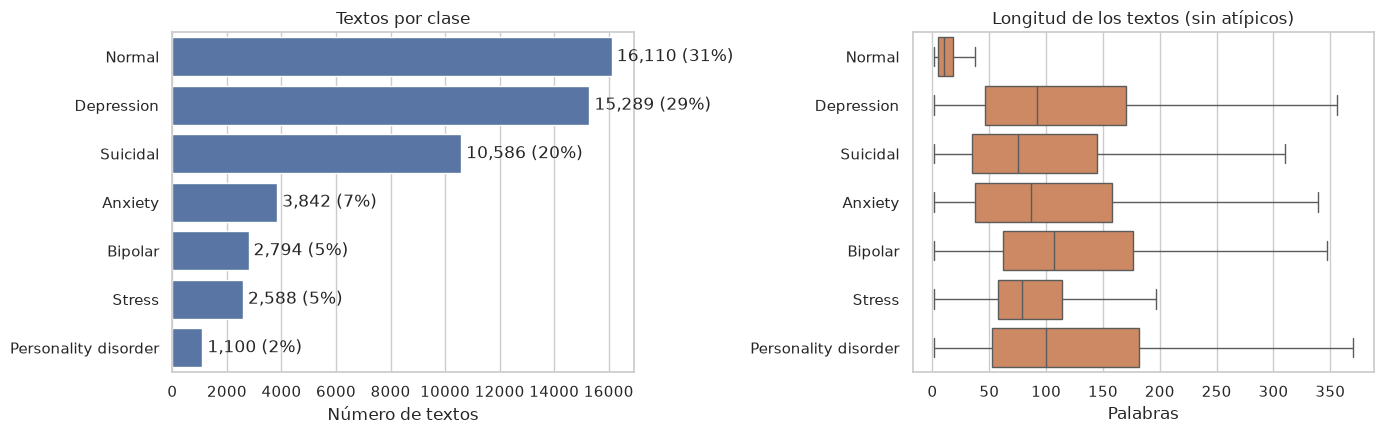

count    52309.0
mean        90.0
std        128.0
min          1.0
50%         53.0
75%        121.0
90%        217.0
95%        298.0
max       5087.0


In [3]:
CLASES = df["status"].value_counts().index.tolist()   # de la más a la menos frecuente
clase_a_id = {c: i for i, c in enumerate(CLASES)}
df["y"] = df["status"].map(clase_a_id)
df["n_palabras"] = df["texto"].str.split().str.len()

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
conteo = df["status"].value_counts()
sns.barplot(x=conteo.values, y=conteo.index, ax=ejes[0], color="#4C72B0")
for i, v in enumerate(conteo.values):
    ejes[0].text(v, i, f" {v:,} ({v/len(df):.0%})", va="center")
ejes[0].set(title="Textos por clase", xlabel="Número de textos", ylabel="")
sns.boxplot(data=df, y="status", x="n_palabras", order=CLASES, ax=ejes[1],
            color="#DD8452", showfliers=False)
ejes[1].set(title="Longitud de los textos (sin atípicos)", xlabel="Palabras", ylabel="")
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "01_datos.png", dpi=120, bbox_inches="tight"); plt.show()

print(df["n_palabras"].describe(percentiles=[.5, .75, .9, .95]).round(0).to_string())

**Observaciones.**
- Las clases están **desbalanceadas** (Normal es ~13 veces más grande que Personality disorder). Por eso la
  métrica principal es el **F1 macro**, que pondera igual a todas las clases; la *accuracy* se reporta como
  referencia.
- Los textos «Normal» son muy cortos (mediana ~10 palabras) y el resto son publicaciones largas. La longitud
  máxima de secuencia es un hiperparámetro importante: el 75 % de los textos tiene menos de ~120 palabras.

### División entrenamiento / validación / prueba

Estratificada 70 / 15 / 15. **Todos los hiperparámetros se eligen con validación**; el conjunto de prueba solo
se usa al final (§7) para no sobreajustar la selección.

In [4]:
x_tmp, x_test, y_tmp, y_test = train_test_split(
    df["texto"].to_numpy(dtype=object), df["y"].to_numpy(), test_size=0.15, stratify=df["y"], random_state=SEMILLA)
x_train, x_val, y_train, y_val = train_test_split(
    x_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEMILLA)
print(f"Entrenamiento: {len(x_train):,} | Validación: {len(x_val):,} | Prueba: {len(x_test):,}")

Entrenamiento: 36,615 | Validación: 7,847 | Prueba: 7,847


## 3. Pipeline: vectorización y arquitectura

```
texto ─► TextVectorization ─► Embedding ─► capa(s) recurrente(s) ─► Dropout ─► Dense(64, ReLU) ─► Dense(7)
         (minúsculas, sin       (vectores      SimpleRNN / LSTM / GRU                              logits
          puntuación, índices)   entrenables)  opcionalmente bidireccional
```

- `TextVectorization` se ajusta **solo con entrenamiento**. Su tamaño de vocabulario y la longitud de secuencia
  son hiperparámetros, así que cacheamos un vectorizador por combinación.
- `mask_zero=True` hace que la RNN ignore el relleno (*padding*) de los textos cortos.
- Entrenamos hasta 10 épocas con **early stopping** sobre la pérdida de validación (paciencia 2) y nos quedamos
  con los mejores pesos.

In [5]:
_cache_vectorizadores = {}

def vectorizar(vocabulario, longitud):
    # Devuelve (train, val, test) como matrices de índices para un (vocabulario, longitud).
    clave = (vocabulario, longitud)
    if clave not in _cache_vectorizadores:
        vec = keras.layers.TextVectorization(max_tokens=vocabulario, output_sequence_length=longitud)
        vec.adapt(list(x_train))
        _cache_vectorizadores[clave] = tuple(np.asarray(vec(list(x))) for x in (x_train, x_val, x_test))
    return _cache_vectorizadores[clave]


def construir_modelo(cfg):
    Celda = {"SimpleRNN": keras.layers.SimpleRNN, "LSTM": keras.layers.LSTM, "GRU": keras.layers.GRU}[cfg["celda"]]
    capas = [keras.Input(shape=(cfg["longitud"],), dtype="int64"),
             keras.layers.Embedding(cfg["vocabulario"], cfg["embedding"], mask_zero=True)]
    for i in range(cfg["capas"]):
        rnn = Celda(cfg["unidades"], return_sequences=i < cfg["capas"] - 1)
        capas.append(keras.layers.Bidirectional(rnn) if cfg["bidireccional"] else rnn)
        capas.append(keras.layers.Dropout(cfg["dropout"]))
    capas += [keras.layers.Dense(64, activation="relu"),
              keras.layers.Dropout(cfg["dropout"]),
              keras.layers.Dense(len(CLASES))]
    modelo = keras.Sequential(capas)
    optimizador = {"adam": keras.optimizers.Adam,
                   "rmsprop": keras.optimizers.RMSprop,
                   "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate, momentum=0.9),
                   }[cfg["optimizador"]](learning_rate=cfg["lr"])
    modelo.compile(optimizer=optimizador,
                   loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   metrics=["accuracy"])
    return modelo


PESOS_BALANCEADOS = dict(enumerate(compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_train)))

def entrenar(cfg, semilla=SEMILLA, verbose=0):
    # Entrena una configuración y devuelve (modelo, métricas en validación, historia).
    keras.utils.set_random_seed(semilla)
    xtr, xva, _ = vectorizar(cfg["vocabulario"], cfg["longitud"])
    modelo = construir_modelo(cfg)
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    inicio = time.time()
    historia = modelo.fit(xtr, y_train, validation_data=(xva, y_val), epochs=10,
                          batch_size=cfg["batch"], callbacks=[parada], verbose=verbose,
                          class_weight=PESOS_BALANCEADOS if cfg["pesos_clase"] else None)
    segundos = time.time() - inicio
    pred = modelo.predict(xva, batch_size=512, verbose=0).argmax(axis=1)
    metricas = {"val_f1_macro": f1_score(y_val, pred, average="macro"),
                "val_accuracy": accuracy_score(y_val, pred),
                "val_loss": min(historia.history["val_loss"]),
                "epocas": len(historia.history["loss"]),
                "mejor_epoca": int(np.argmin(historia.history["val_loss"])) + 1,
                "segundos": segundos,
                "parametros": modelo.count_params()}
    return modelo, metricas, historia.history

## 4. Punto 1 — Entrenar una RNN (modelo base)

Configuración base, elegida con valores típicos razonables. Cada experimento de §5 cambia **un solo**
hiperparámetro respecto a esta base.

In [6]:
BASE = {"celda": "LSTM", "bidireccional": True, "unidades": 64, "capas": 1, "embedding": 64,
        "dropout": 0.2, "lr": 1e-3, "batch": 64, "vocabulario": 20_000, "longitud": 128,
        "optimizador": "adam", "pesos_clase": False}

modelo_base, metricas_base, historia_base = entrenar(BASE, verbose=2)
modelo_base.save(RUTA_MODELOS / "modelo_base.keras")
modelo_base.summary()
print({k: round(v, 4) if isinstance(v, float) else v for k, v in metricas_base.items()})

Epoch 1/10


E0000 00:00:1791909204.610508  614891 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


573/573 - 23s - 41ms/step - accuracy: 0.5569 - loss: 1.1475 - val_accuracy: 0.6309 - val_loss: 0.9203


Epoch 2/10


573/573 - 22s - 38ms/step - accuracy: 0.6800 - loss: 0.8150 - val_accuracy: 0.6516 - val_loss: 0.8950


...

 Total params: 4,064,279 (15.50 MB)

 Trainable params: 1,354,759 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,709,520 (10.34 MB)

{'val_f1_macro': 0.5962, 'val_accuracy': 0.6942, 'val_loss': 0.8754, 'epocas': 5, 'mejor_epoca': 3, 'segundos': 107.529, 'parametros': 1354759}


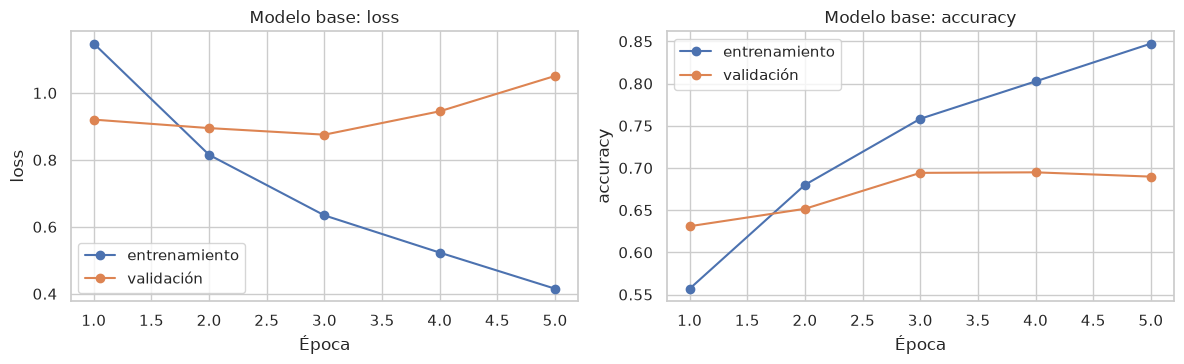

In [7]:
def graficar_historia(h, titulo, archivo=None):
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    for eje, m in zip(ejes, ["loss", "accuracy"]):
        eje.plot(range(1, len(h[m]) + 1), h[m], "o-", label="entrenamiento")
        eje.plot(range(1, len(h[m]) + 1), h["val_" + m], "o-", label="validación")
        eje.set(xlabel="Época", ylabel=m, title=f"{titulo}: {m}"); eje.legend()
    plt.tight_layout()
    if archivo: plt.savefig(RUTA_FIGURAS / archivo, dpi=120, bbox_inches="tight")
    plt.show()

graficar_historia(historia_base, "Modelo base", "02_curvas_base.png")

## 5. Punto 2 — Ajuste de hiperparámetros

**Diseño del experimento: un factor a la vez (*one-factor-at-a-time*).** Partiendo de la base, cambiamos un
hiperparámetro y dejamos los demás fijos. Así cada diferencia de desempeño se puede atribuir a ese
hiperparámetro. Una búsqueda en rejilla completa (3 × 2 × 3 × 2 × 3 × 3 × 3 × 3 × 3 × 3 × 3 × 2 ≈ 190.000
combinaciones) es inviable en CPU (~1 min por época).

| Hiperparámetro | Base | Alternativas | Qué controla |
|---|---|---|---|
| Tipo de celda | LSTM | SimpleRNN, GRU | Memoria de largo plazo (compuertas) |
| Bidireccional | Sí | No | Leer el texto en ambos sentidos |
| Unidades | 64 | 32, 128 | Capacidad del estado oculto |
| Capas recurrentes | 1 | 2 | Profundidad |
| Dimensión del embedding | 64 | 32, 128 | Riqueza de la representación de cada palabra |
| Dropout | 0.2 | 0.0, 0.5 | Regularización |
| Tasa de aprendizaje | 1e-3 | 3e-4, 3e-3 | Tamaño del paso del optimizador |
| Tamaño de lote | 64 | 32, 128 | Ruido del gradiente y velocidad |
| Vocabulario | 20.000 | 5.000, 10.000 | Palabras distintas que el modelo conoce |
| Longitud de secuencia | 128 | 64, 256 | Cuántas palabras de cada texto se leen |
| Optimizador | Adam | RMSprop, SGD (momentum 0.9) | Regla de actualización de pesos |
| Pesos por clase | No | Balanceados | Compensar el desbalance de clases |

**Ruido experimental.** Repetimos la base con otras 2 semillas. La desviación estándar de esas 3 corridas nos
dice qué diferencias son reales y cuáles son azar de la inicialización.

Los resultados se guardan en `resultados/experimentos.csv` después de cada corrida: si el notebook se
interrumpe, al volver a ejecutarlo continúa donde quedó.

In [8]:
VARIACIONES = {
    "celda": ["SimpleRNN", "GRU"], "bidireccional": [False], "unidades": [32, 128], "capas": [2],
    "embedding": [32, 128], "dropout": [0.0, 0.5], "lr": [3e-4, 3e-3], "batch": [32, 128],
    "vocabulario": [5_000, 10_000], "longitud": [64, 256], "optimizador": ["rmsprop", "sgd"],
    "pesos_clase": [True],
}

experimentos = [("base", "-", "base", BASE, SEMILLA)]
experimentos += [(f"base_semilla_{s}", "semilla", s, BASE, s) for s in (7, 2024)]
for factor, valores in VARIACIONES.items():
    for v in valores:
        experimentos.append((f"{factor}={v}", factor, v, {**BASE, factor: v}, SEMILLA))
print(len(experimentos), "corridas en total")

24 corridas en total


In [9]:
resultados = pd.read_csv(ARCHIVO_EXPERIMENTOS) if ARCHIVO_EXPERIMENTOS.exists() else pd.DataFrame()
historias = json.loads(ARCHIVO_HISTORIAS.read_text()) if ARCHIVO_HISTORIAS.exists() else {}
hechos = set(resultados["id"]) if len(resultados) else set()

for id_exp, factor, valor, cfg, semilla in experimentos:
    if id_exp in hechos:
        continue
    if id_exp == "base":   # ya entrenado en §4
        metricas, historia = metricas_base, historia_base
    else:
        modelo, metricas, historia = entrenar(cfg, semilla=semilla)
        keras.backend.clear_session()
    fila = {"id": id_exp, "factor": factor, "valor": str(valor), "semilla": semilla, **cfg, **metricas}
    resultados = pd.concat([resultados, pd.DataFrame([fila])], ignore_index=True)
    resultados.to_csv(ARCHIVO_EXPERIMENTOS, index=False)
    historias[id_exp] = {k: [float(x) for x in v] for k, v in historia.items()}
    ARCHIVO_HISTORIAS.write_text(json.dumps(historias))
    print(f"{id_exp:<24} F1-macro={metricas['val_f1_macro']:.4f}  acc={metricas['val_accuracy']:.4f}  "
          f"épocas={metricas['epocas']:>2}  {metricas['segundos']/60:5.1f} min")

print("Corridas completas:", len(resultados))

base                     F1-macro=0.5962  acc=0.6942  épocas= 5    1.8 min


base_semilla_7           F1-macro=0.5463  acc=0.6924  épocas= 4    1.4 min


base_semilla_2024        F1-macro=0.5377  acc=0.6915  épocas= 4    1.5 min


celda=SimpleRNN          F1-macro=0.4330  acc=0.6382  épocas= 4    0.8 min


celda=GRU                F1-macro=0.5194  acc=0.6831  épocas= 4    1.6 min


...

longitud=64              F1-macro=0.5661  acc=0.6753  épocas= 4    0.9 min


longitud=256             F1-macro=0.5758  acc=0.6859  épocas= 4    2.7 min


optimizador=rmsprop      F1-macro=0.6057  acc=0.6917  épocas= 7    2.6 min


optimizador=sgd          F1-macro=0.1995  acc=0.5438  épocas=10    3.5 min


pesos_clase=True         F1-macro=0.5937  acc=0.6592  épocas= 5    1.8 min
Corridas completas: 24


## 6. Punto 3 — Análisis comparativo: hiperparámetros vs. desempeño

In [10]:
semillas = resultados[resultados["id"].str.startswith("base")]
F1_BASE = resultados.loc[resultados["id"] == "base", "val_f1_macro"].item()
RUIDO = semillas["val_f1_macro"].std()
print(f"F1-macro base (3 semillas): media {semillas['val_f1_macro'].mean():.4f} ± {RUIDO:.4f} (desv. estándar)")
print(f"Accuracy base (3 semillas): media {semillas['val_accuracy'].mean():.4f} ± {semillas['val_accuracy'].std():.4f}")

tabla = resultados[resultados["factor"].isin(list(VARIACIONES))].copy()
tabla["Δ F1 vs base"] = tabla["val_f1_macro"] - F1_BASE
tabla["¿supera el ruido?"] = np.where(tabla["Δ F1 vs base"].abs() > 2 * RUIDO,
                                       np.where(tabla["Δ F1 vs base"] > 0, "mejora", "empeora"), "≈ igual")
columnas = ["factor", "valor", "val_f1_macro", "val_accuracy", "Δ F1 vs base", "¿supera el ruido?",
            "mejor_epoca", "segundos", "parametros"]
(tabla[columnas].sort_values("val_f1_macro", ascending=False)
     .style.format({"val_f1_macro": "{:.4f}", "val_accuracy": "{:.4f}", "Δ F1 vs base": "{:+.4f}",
                    "segundos": "{:.0f}", "parametros": "{:,}"})
     .background_gradient(subset=["Δ F1 vs base"], cmap="RdYlGn", vmin=-0.05, vmax=0.05))

F1-macro base (3 semillas): media 0.5601 ± 0.0316 (desv. estándar)
Accuracy base (3 semillas): media 0.6927 ± 0.0014


,factor,valor,val_f1_macro,val_accuracy,Δ F1 vs base,¿supera el ruido?,mejor_epoca,segundos,parametros
14,lr,0.003,0.6254,0.6884,+0.0292,≈ igual,2,87,"1,354,759"
10,embedding,128,0.6175,0.7073,+0.0213,≈ igual,2,100,"2,667,527"
18,vocabulario,10000,0.6071,0.6972,+0.0109,≈ igual,3,112,"714,759"
21,optimizador,rmsprop,0.6057,0.6917,+0.0095,≈ igual,5,157,"1,354,759"
23,pesos_clase,True,0.5937,0.6592,-0.0025,≈ igual,3,109,"1,354,759"
9,embedding,32,0.5915,0.6883,-0.0047,≈ igual,3,101,"698,375"
7,unidades,128,0.5890,0.6773,-0.0071,≈ igual,3,243,"1,494,535"
15,batch,32,0.5867,0.6903,-0.0095,≈ igual,2,131,"1,354,759"
20,longitud,256,0.5758,0.6859,-0.0204,≈ igual,2,163,"1,354,759"
19,longitud,64,0.5661,0.6753,-0.0300,≈ igual,2,52,"1,354,759"


**Criterio.** Consideramos que un cambio *mejora* o *empeora* el modelo solo si la diferencia con la base es mayor
que **2 desviaciones estándar** del ruido entre semillas; si no, decimos que es «≈ igual».

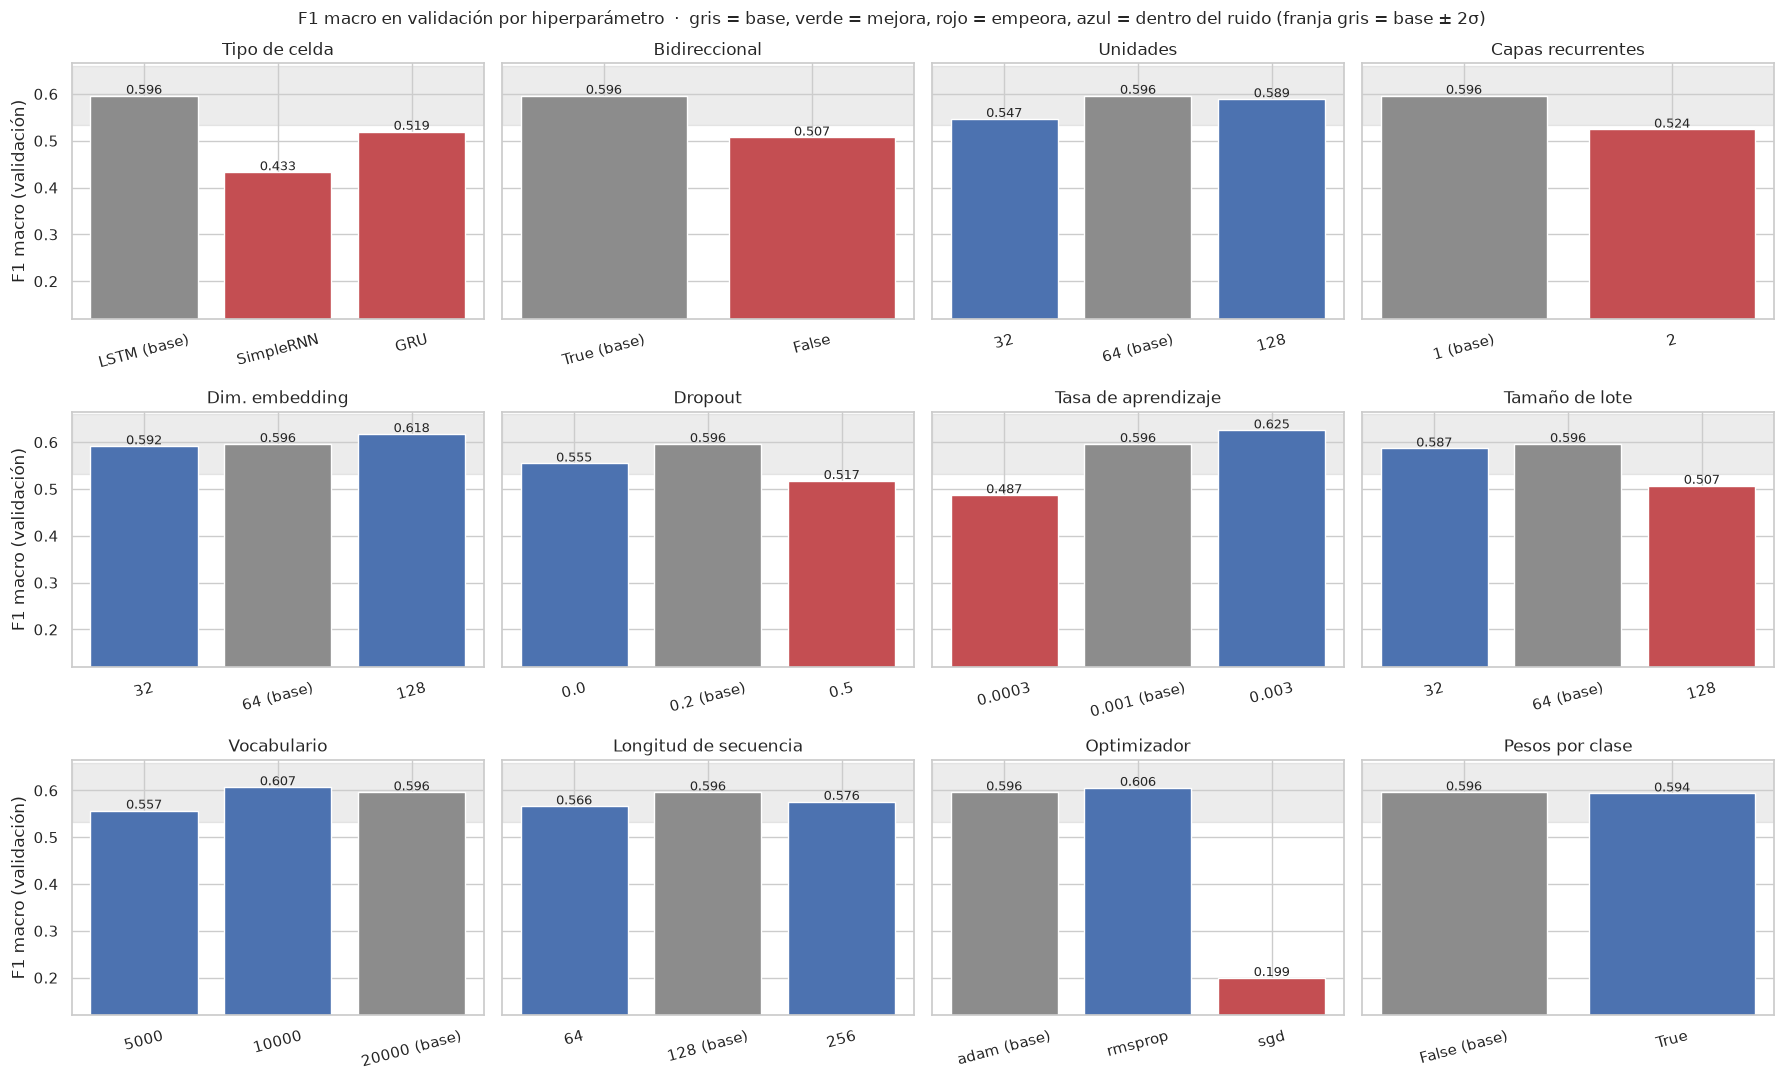

In [11]:
NOMBRES = {"celda": "Tipo de celda", "bidireccional": "Bidireccional", "unidades": "Unidades",
           "capas": "Capas recurrentes", "embedding": "Dim. embedding", "dropout": "Dropout",
           "lr": "Tasa de aprendizaje", "batch": "Tamaño de lote", "vocabulario": "Vocabulario",
           "longitud": "Longitud de secuencia", "optimizador": "Optimizador", "pesos_clase": "Pesos por clase"}

fig, ejes = plt.subplots(3, 4, figsize=(18, 11), sharey=True)
for eje, (factor, valores) in zip(ejes.flat, VARIACIONES.items()):
    filas = [("base", str(BASE[factor]), F1_BASE)] + [
        ("alt", str(v), resultados.loc[resultados["id"] == f"{factor}={v}", "val_f1_macro"].item())
        for v in valores if f"{factor}={v}" in set(resultados["id"])]
    if isinstance(BASE[factor], (int, float)) and not isinstance(BASE[factor], bool):
        filas.sort(key=lambda f: float(f[1]))
    etiquetas = [f[1] + (" (base)" if f[0] == "base" else "") for f in filas]
    colores = ["#8C8C8C" if f[0] == "base" else ("#55A868" if f[2] - F1_BASE > 2 * RUIDO else
               "#C44E52" if F1_BASE - f[2] > 2 * RUIDO else "#4C72B0") for f in filas]
    eje.bar(etiquetas, [f[2] for f in filas], color=colores)
    eje.axhspan(F1_BASE - 2 * RUIDO, F1_BASE + 2 * RUIDO, color="grey", alpha=0.15, zorder=0)
    for i, f in enumerate(filas):
        eje.text(i, f[2] + 0.004, f"{f[2]:.3f}", ha="center", fontsize=9)
    eje.set_title(NOMBRES[factor]); eje.tick_params(axis="x", rotation=15)
minimo = resultados["val_f1_macro"].min()
ejes[0, 0].set_ylim(max(0, minimo - 0.08), resultados["val_f1_macro"].max() + 0.04)
for eje in ejes[:, 0]: eje.set_ylabel("F1 macro (validación)")
fig.suptitle("F1 macro en validación por hiperparámetro  ·  gris = base, verde = mejora, rojo = empeora, "
             "azul = dentro del ruido (franja gris = base ± 2σ)", fontsize=12)
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "03_hiperparametros.png", dpi=120, bbox_inches="tight"); plt.show()

### Importancia de cada hiperparámetro

Medimos la importancia como el **rango** de F1 macro que produce el hiperparámetro (mejor valor − peor valor,
incluyendo la base). Un rango grande significa que equivocarse en ese hiperparámetro cuesta mucho.

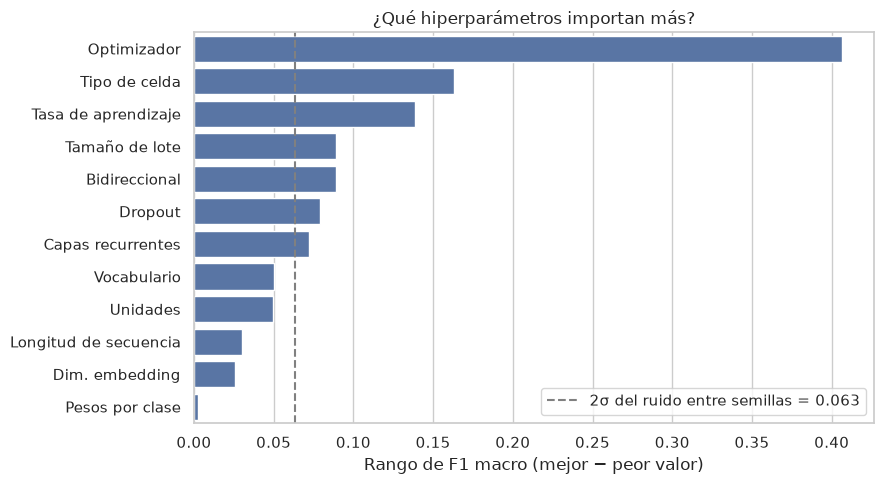

,hiperparámetro,rango_F1
10,Optimizador,0.4062
0,Tipo de celda,0.1632
6,Tasa de aprendizaje,0.1384
7,Tamaño de lote,0.0892
1,Bidireccional,0.0891
5,Dropout,0.0789
3,Capas recurrentes,0.0720
8,Vocabulario,0.0501
2,Unidades,0.0495
9,Longitud de secuencia,0.0300


In [12]:
importancia = []
for factor, valores in VARIACIONES.items():
    f1s = [F1_BASE] + [resultados.loc[resultados["id"] == f"{factor}={v}", "val_f1_macro"].item()
                       for v in valores if f"{factor}={v}" in set(resultados["id"])]
    importancia.append({"hiperparámetro": NOMBRES[factor], "rango_F1": max(f1s) - min(f1s)})
importancia = pd.DataFrame(importancia).sort_values("rango_F1", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=importancia, x="rango_F1", y="hiperparámetro", color="#4C72B0")
plt.axvline(2 * RUIDO, color="grey", ls="--", label=f"2σ del ruido entre semillas = {2*RUIDO:.3f}")
plt.xlabel("Rango de F1 macro (mejor − peor valor)"); plt.ylabel(""); plt.legend()
plt.title("¿Qué hiperparámetros importan más?")
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "04_importancia.png", dpi=120, bbox_inches="tight"); plt.show()
importancia.round(4)

### Costo computacional vs. desempeño

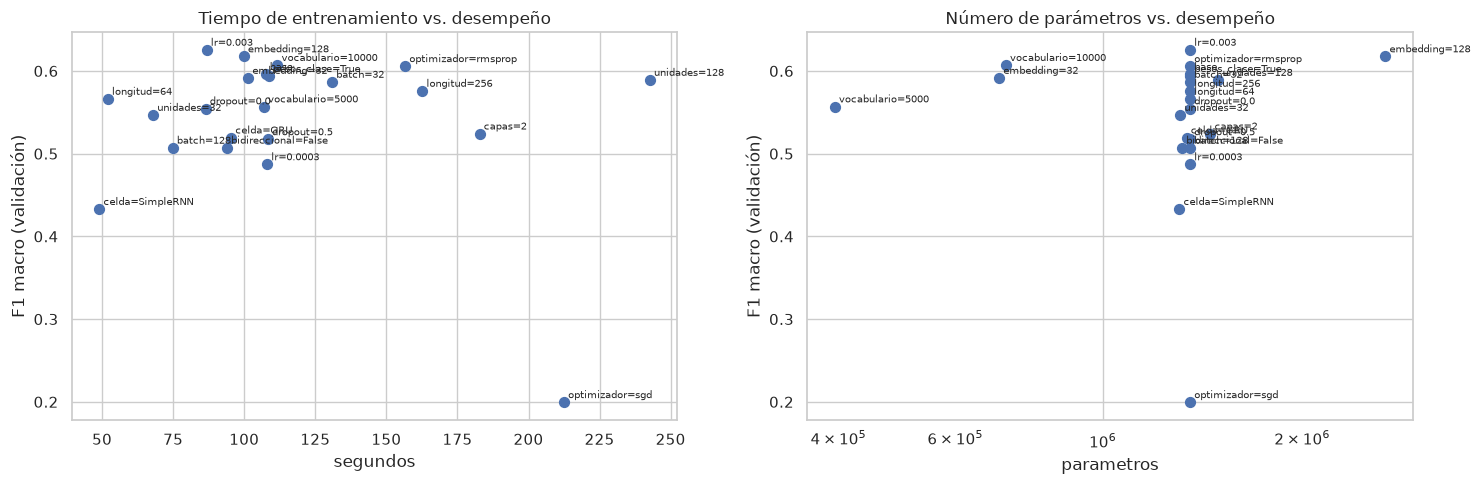

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
datos_graf = resultados[resultados["factor"] != "semilla"]
for eje, x, titulo in [(ejes[0], "segundos", "Tiempo de entrenamiento"),
                       (ejes[1], "parametros", "Número de parámetros")]:
    eje.scatter(datos_graf[x], datos_graf["val_f1_macro"], s=50, color="#4C72B0")
    for _, fila in datos_graf.iterrows():
        eje.annotate(fila["id"], (fila[x], fila["val_f1_macro"]), fontsize=7.5,
                     xytext=(3, 3), textcoords="offset points")
    eje.set(xlabel=x, ylabel="F1 macro (validación)", title=f"{titulo} vs. desempeño")
ejes[1].set_xscale("log")
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "05_costo.png", dpi=120, bbox_inches="tight"); plt.show()

### Curvas de aprendizaje de los factores más influyentes

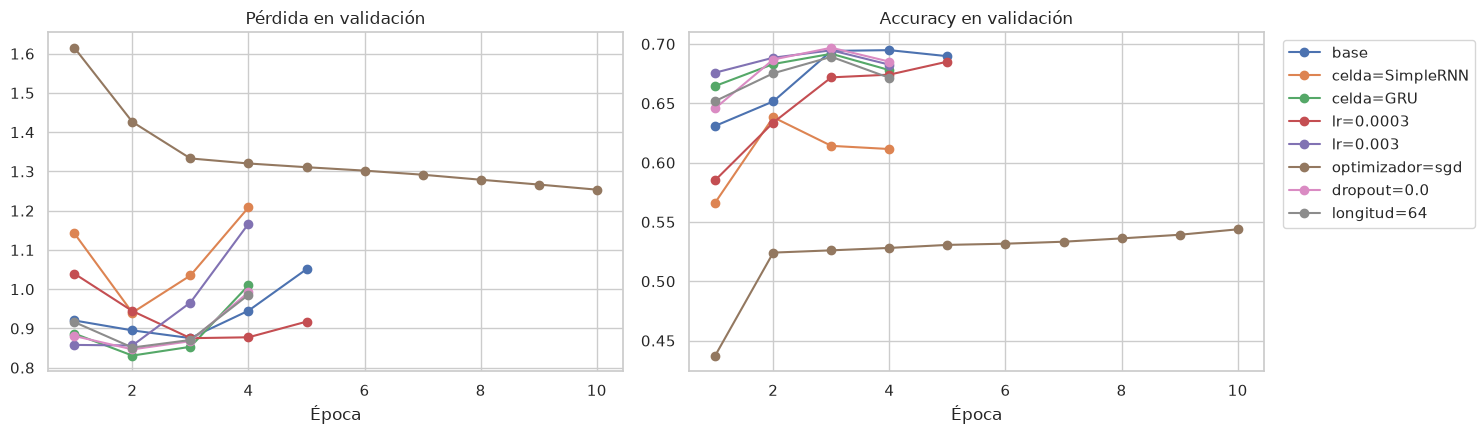

In [14]:
seleccion = ["base", "celda=SimpleRNN", "celda=GRU", "lr=0.0003", "lr=0.003", "optimizador=sgd",
             "dropout=0.0", "longitud=64"]
seleccion = [s for s in seleccion if s in historias]
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
for s in seleccion:
    h = historias[s]; epocas = range(1, len(h["val_loss"]) + 1)
    ejes[0].plot(epocas, h["val_loss"], "o-", label=s)
    ejes[1].plot(epocas, h["val_accuracy"], "o-", label=s)
ejes[0].set(title="Pérdida en validación", xlabel="Época"); ejes[1].set(title="Accuracy en validación", xlabel="Época")
ejes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "06_curvas_factores.png", dpi=120, bbox_inches="tight"); plt.show()

### Análisis de los resultados

**1. El ruido entre semillas es grande.** Con exactamente la misma configuración, el F1 macro de la base varía
entre 0,538 y 0,596 (media 0,560, σ = 0,032). El umbral de 2σ es entonces **±0,063**. En cambio, la *accuracy*
casi no se mueve (0,693 ± 0,001). La diferencia se explica por las clases pequeñas (Stress, Personality disorder):
unos pocos aciertos más o menos en ellas cambian mucho el F1 macro, pero apenas la accuracy. Además, la semilla 42
(la que usan todas las variaciones) resultó ser la **mejor** de las tres, así que la base de referencia es
«afortunada» y favorece que las alternativas parezcan peores.

**2. Ninguna variación mejora la base más allá del ruido.** Las mejores alternativas fueron `lr = 3e-3`
(+0,029), `embedding = 128` (+0,021), `vocabulario = 10.000` (+0,011) y RMSprop (+0,010); todas quedan dentro de la
franja de ±2σ. Son candidatas a confirmar con más semillas, no mejoras demostradas.

**3. Lo que sí empeora claramente.** Ocho cambios caen más de 2σ por debajo de la base. Para no depender de la
semilla afortunada, también los comparamos contra la **media** de las tres semillas (0,560 − 2σ = 0,497). Solo tres
siguen siendo malos con ese criterio más exigente:

| Cambio | F1 macro | Δ vs base | Por qué |
|---|---|---|---|
| Optimizador SGD | 0,200 | −0,397 | Con lr = 1e-3 SGD avanza demasiado lento: a las 10 épocas la pérdida sigue bajando (curvas). Necesitaría una tasa ~10–100 veces mayor; no es culpa del optimizador en sí. |
| Celda SimpleRNN | 0,433 | −0,163 | Sin compuertas, el gradiente se desvanece en textos de 128 palabras: la pérdida de validación sube desde la época 2. |
| lr = 3e-4 | 0,487 | −0,109 | Aprende lento y el *early stopping* (paciencia 2) lo detiene antes de converger. |

Los otros cinco (lote 128, unidireccional, dropout 0,5, GRU, 2 capas; Δ entre −0,07 y −0,09) empeoran frente a la
semilla 42 pero quedan cerca del borde frente a la media, así que la evidencia es más débil.

**4. Importancia de los hiperparámetros.** Ordenados por rango de F1: optimizador ≫ tipo de celda > tasa de
aprendizaje > tamaño de lote ≈ bidireccional > dropout > capas. Los tres primeros controlan **si el modelo logra
aprender** (optimización y flujo del gradiente). Los de **capacidad y representación** (unidades, dimensión del
embedding, vocabulario, longitud de secuencia) tienen rangos menores que el ruido: entre los valores probados,
el modelo es robusto a ellos.

**5. Pesos por clase.** Casi no cambian el F1 macro (−0,003), pero bajan la accuracy de 0,694 a 0,659. El modelo
cambia aciertos en Normal/Depression por aciertos en clases pequeñas, sin ganancia neta.

**6. Costo vs. desempeño.** Más parámetros o más tiempo no compran desempeño. `unidades = 128` cuesta 2,3 veces el
tiempo de la base y `capas = 2` 1,7 veces, sin mejorar. `vocabulario = 10.000` usa la mitad de parámetros
(0,71 M vs 1,35 M) con el mismo F1. `longitud = 64` entrena en la mitad del tiempo perdiendo solo 0,03 (dentro del
ruido). Todo el barrido de 24 corridas tardó ~45 min en CPU.

**7. Sobreajuste rápido.** En casi todas las corridas la pérdida de validación toca su mínimo en la época 2–3 y
luego sube, mientras la de entrenamiento sigue bajando. El *early stopping* con `restore_best_weights` es
esencial: sin él, el modelo memoriza el entrenamiento.

## 7. Modelo final y evaluación en prueba

Construimos el modelo final tomando, para cada hiperparámetro, el valor con mejor F1 macro en validación,
**pero solo si su mejora supera 2σ del ruido**; si no, mantenemos el valor base (es más simple y no hay evidencia
de que el cambio ayude). Como las mejoras de distintos factores pueden no sumarse (interacciones), comparamos el
modelo combinado contra la base en validación y en **prueba**, que hasta ahora no se había tocado.

In [15]:
FINAL = dict(BASE)
for factor in VARIACIONES:
    candidatos = tabla[(tabla["factor"] == factor) & (tabla["Δ F1 vs base"] > 2 * RUIDO)]
    if len(candidatos):
        mejor = candidatos.sort_values("val_f1_macro").iloc[-1]
        FINAL[factor] = type(BASE[factor])(mejor[factor])
cambios = {k: (BASE[k], v) for k, v in FINAL.items() if v != BASE[k]}
print("Cambios respecto a la base:", cambios or "ninguno")

if cambios:
    modelo_final, metricas_final, historia_final = entrenar(FINAL, verbose=2)
    modelo_final.save(RUTA_MODELOS / "modelo_final.keras")
    graficar_historia(historia_final, "Modelo final", "07_curvas_final.png")
else:
    modelo_final, metricas_final, historia_final = modelo_base, metricas_base, historia_base
print({k: round(v, 4) if isinstance(v, float) else v for k, v in metricas_final.items()})

Cambios respecto a la base: ninguno
{'val_f1_macro': 0.5962, 'val_accuracy': 0.6942, 'val_loss': 0.8754, 'epocas': 5, 'mejor_epoca': 3, 'segundos': 107.529, 'parametros': 1354759}


In [16]:
def evaluar_prueba(modelo, cfg):
    _, _, xte = vectorizar(cfg["vocabulario"], cfg["longitud"])
    return modelo.predict(xte, batch_size=512, verbose=0).argmax(axis=1)

pred_base, pred_final = evaluar_prueba(modelo_base, BASE), evaluar_prueba(modelo_final, FINAL)
comparacion = pd.DataFrame({
    "modelo": ["Base", "Final"],
    "val_F1_macro": [metricas_base["val_f1_macro"], metricas_final["val_f1_macro"]],
    "test_F1_macro": [f1_score(y_test, p, average="macro") for p in (pred_base, pred_final)],
    "test_F1_ponderado": [f1_score(y_test, p, average="weighted") for p in (pred_base, pred_final)],
    "test_accuracy": [accuracy_score(y_test, p) for p in (pred_base, pred_final)],
}).round(4)
comparacion.to_csv(RUTA_RESULTADOS / "comparacion_test.csv", index=False)
comparacion

,modelo,val_F1_macro,test_F1_macro,test_F1_ponderado,test_accuracy
0,Base,0.5962,0.605,0.6946,0.6994
1,Final,0.5962,0.605,0.6946,0.6994


                      precision    recall  f1-score   support

              Normal      0.913     0.859     0.885      2417
          Depression      0.579     0.757     0.656      2294
            Suicidal      0.618     0.501     0.553      1588
             Anxiety      0.697     0.736     0.716       576
             Bipolar      0.746     0.702     0.723       419
              Stress      0.578     0.345     0.432       388
Personality disorder      0.517     0.182     0.269       165

            accuracy                          0.699      7847
           macro avg      0.664     0.583     0.605      7847
        weighted avg      0.706     0.699     0.695      7847



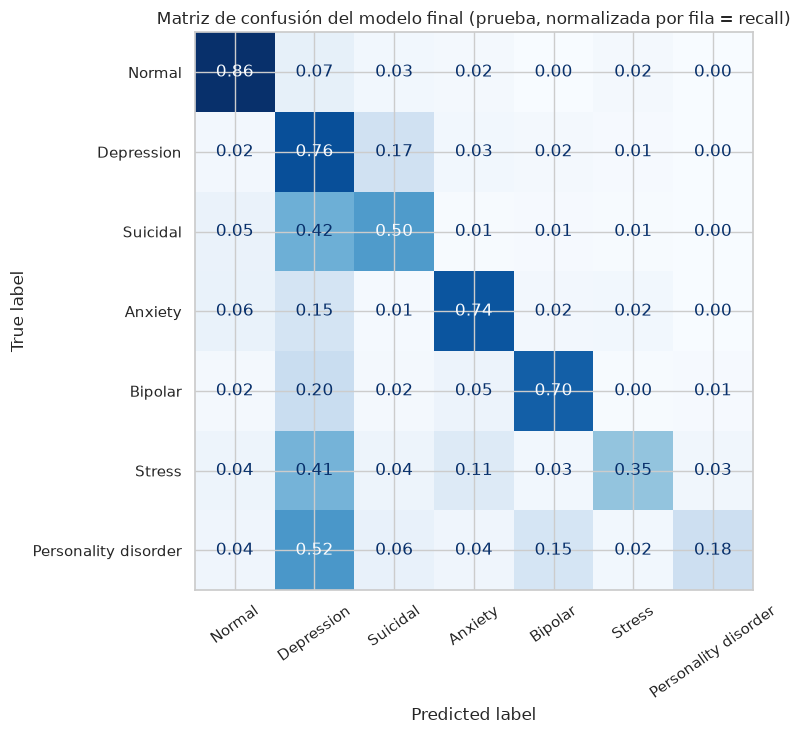

In [17]:
print(classification_report(y_test, pred_final, target_names=CLASES, digits=3, zero_division=0))
reporte = pd.DataFrame(classification_report(y_test, pred_final, target_names=CLASES, output_dict=True, zero_division=0)).T
reporte.round(4).to_csv(RUTA_RESULTADOS / "reporte_clases_final.csv")

fig, eje = plt.subplots(figsize=(9, 7.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final, normalize="true"), display_labels=CLASES).plot(
    ax=eje, cmap="Blues", values_format=".2f", xticks_rotation=35, colorbar=False)
eje.set_title("Matriz de confusión del modelo final (prueba, normalizada por fila = recall)")
plt.tight_layout(); plt.savefig(RUTA_FIGURAS / "08_confusion_final.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Conclusiones

1. **Punto 1.** Una LSTM bidireccional (64 unidades, embedding de 64, Adam 1e-3) alcanza en **prueba** un
   **F1 macro de 0,605** y una **accuracy de 0,699** en 7 clases, muy por encima del azar (1/7 ≈ 0,14).
2. **Punto 2.** Probamos 12 hiperparámetros (21 variaciones) más 2 semillas extra. **Ninguna variación superó el
   ruido experimental**, así que el modelo final es la propia base. Es el resultado honesto: preferimos no elegir un
   «ganador» que podría serlo solo por azar.
3. **Punto 3.** Los hiperparámetros que más importan son los de **optimización** (optimizador, tasa de
   aprendizaje, lote) y el **tipo de celda**: deciden si la red aprende o no. Las compuertas de la LSTM/GRU son
   necesarias para textos largos. Los de capacidad (unidades, capas, embedding, vocabulario, longitud) apenas
   influyen en el rango probado; sirven más para reducir costo que para ganar desempeño.
4. **Por clase.** El modelo distingue bien Normal (F1 0,89), Bipolar (0,72) y Anxiety (0,72). Las clases difíciles
   son **Suicidal** (la mitad se confunde con Depression, que es semánticamente muy cercana), **Stress** (0,43) y
   **Personality disorder** (0,27, recall 0,18), que son las de menos ejemplos y se «absorben» en Depression.
5. **Lección metodológica.** Con clases desbalanceadas, una sola corrida por configuración no basta para comparar:
   el F1 macro varía ±0,03 solo por la semilla, lo mismo que la mayoría de los efectos medidos.

**Limitaciones y siguientes pasos.**
- Repetir las mejores candidatas (`lr = 3e-3`, `embedding = 128`, `vocabulario = 10.000`, RMSprop) con 3–5
  semillas y comparar medias, no corridas sueltas.
- Darle a SGD una tasa de aprendizaje acorde (≈ 1e-2 a 1e-1) para una comparación justa de optimizadores.
- El diseño de un factor a la vez no detecta **interacciones** (p. ej., una tasa de aprendizaje mayor podría
  combinar mejor con un lote más grande).
- Usar embeddings preentrenados en español (p. ej. FastText) o un modelo tipo BERT, que probablemente separaría
  mejor Depression de Suicidal.
- Los textos son traducciones automáticas; parte del error puede venir de la traducción y de etiquetas ruidosas.